## *ML Assignment 2*
Name: Dhruv

BITS ID: 2026CT05090

Date: 26-Nov-2026

Dataset: Thyroid Disease Data (Kaggle) | Task: Binary classification (Normal vs Thyroid condition)

### 1. Imports

In [44]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42

### 2. Load Dataset

In [45]:
url = "https://raw.githubusercontent.com/2026ct05090/2026ct05090_ML_Assignment-2/refs/heads/main/thyroidDF.csv"

try:
    raw = pd.read_csv(url)
    print("loaded from github")
except Exception as e:
    print("github load failed:", e)
    print("trying kaggle...")
    !pip install -q kagglehub
    import kagglehub
    folder = kagglehub.dataset_download("emmanuelfwerr/thyroid-disease-data")
    raw = pd.read_csv(os.path.join(folder, "thyroidDF.csv"))
    print("loaded from kaggle")

print("shape:", raw.shape)
raw.head()

loaded from github
shape: (9172, 31)


,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_meds,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target,patient_id
0,29,F,f,f,f,f,f,f,f,t,...,NaN,f,NaN,f,NaN,f,NaN,other,-,840801013
1,29,F,f,f,f,f,f,f,f,f,...,128.0,f,NaN,f,NaN,f,NaN,other,-,840801014
2,41,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,11.0,other,-,840801042
3,36,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,26.0,other,-,840803046
4,32,F,f,f,f,f,f,f,f,f,...,NaN,f,NaN,f,NaN,t,36.0,other,S,840803047


### 3. Target variable and feature types
The target column has 32 different codes. "-" means the person has no thyroid problem and the rest are different conditions. Many of the codes have very few rows, so I can't train on them one by one.

So I made it a two class problem:
- 0 = normal
- 1 = has a thyroid condition

Features are of three kinds: numbers (age, TSH, T3, TT4, T4U, FTI), categories (sex, referral_source) and yes/no flags (like on_thyroxine, pregnant, TSH_measured).

In [46]:
df = raw.copy()
df["target"] = (df["target"] != "-").astype(int)

print("shape:", df.shape)
print(df.drop(columns="target").dtypes.value_counts())
print()
print(raw["target"].value_counts())

shape: (9172, 31)
object     22
float64     6
int64       2
Name: count, dtype: int64

target
-      6771
K       436
G       359
I       346
F       233
R       196
A       147
L       115
M       111
N       110
S        85
GK       49
AK       46
J        30
B        21
MK       16
O        14
Q        14
C|I      12
KJ       11
GI       10
H|K       8
D         8
FK        6
C         6
P         5
MI        2
LJ        1
GKJ       1
OI        1
D|R       1
E         1
Name: count, dtype: int64


### 4. Class distribution

target
0    6771
1    2401
Name: count, dtype: int64
target
0    73.82
1    26.18
Name: count, dtype: float64


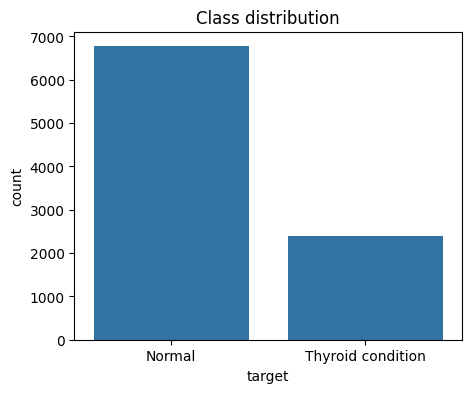

In [47]:
counts = df["target"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2))

plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=df)
plt.xticks([0, 1], ["Normal", "Thyroid condition"])
plt.title("Class distribution")
plt.show()

### 5. Missing values and wrong values

In [48]:
missing = df.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["percent"] = (missing["missing"] / len(df) * 100).round(2)
print(missing)

print()
print(df["age"].describe())
print(df[df["age"] > 120][["age"]])

     missing  percent
sex      307     3.35
TSH      842     9.18
T3      2604    28.39
TT4      442     4.82
T4U      809     8.82
FTI      802     8.74
TBG     8823    96.19

count     9172.000000
mean        73.555822
std       1183.976718
min          1.000000
25%         37.000000
50%         55.000000
75%         68.000000
max      65526.000000
Name: age, dtype: float64
        age
2976    455
5710  65511
6392  65512
8105  65526


### 6. Cleaning
What I did here:
- removed patient_id because it is just an ID
- removed TBG and TBG_measured because almost all of TBG (96%) is missing
- some ages are impossible (like 65526), so I made them missing and fill them later
- removed duplicate rows
- changed the t/f columns to 1/0

In [49]:
df = df.drop(columns=["patient_id", "TBG", "TBG_measured"])

bad_age = (df["age"] > 120) | (df["age"] < 0)
n_bad_age = int(bad_age.sum())
df.loc[bad_age, "age"] = np.nan
print("impossible ages set to missing:", n_bad_age)

n_dup = int(df.duplicated().sum())
print("duplicates found:", n_dup)
df = df.drop_duplicates().reset_index(drop=True)
print("duplicates after:", df.duplicated().sum())
print("shape now:", df.shape)

tf_cols = [c for c in df.columns if set(df[c].dropna().unique()) <= {"t", "f"}]
for c in tf_cols:
    df[c] = df[c].map({"t": 1, "f": 0})
print("converted", len(tf_cols), "yes/no columns to 1/0")

after = df["target"].value_counts()
print("class counts after cleaning:", after.to_dict())
print("class % after cleaning:", (after / len(df) * 100).round(2).to_dict())

impossible ages set to missing: 4
duplicates found: 102
duplicates after: 0
shape now: (9070, 28)
converted 19 yes/no columns to 1/0
class counts after cleaning: {0: 6690, 1: 2380}
class % after cleaning: {0: 73.76, 1: 26.24}


### 7. Train test split
80% train and 20% test. I used stratify so both parts keep the same normal/thyroid ratio, and a fixed seed so the result is the same every time. I also save the test part as test_data.csv for the repo.

In [50]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
print("train:", X_train.shape, " test:", X_test.shape)
print("train class counts:", y_train.value_counts().to_dict())
print("test class counts: ", y_test.value_counts().to_dict())
print("train class %:", y_train.value_counts(normalize=True).round(3).to_dict())
print("test class %: ", y_test.value_counts(normalize=True).round(3).to_dict())

test_data = X_test.copy()
test_data["target"] = y_test
test_data.to_csv("test_data.csv", index=False)

train: (7256, 27)  test: (1814, 27)
train class counts: {0: 5352, 1: 1904}
test class counts:  {0: 1338, 1: 476}
train class %: {0: 0.738, 1: 0.262}
test class %:  {0: 0.738, 1: 0.262}


### 8. Preprocessing
I put all the preprocessing in a pipeline. This way the imputer, scaler and encoder learn only from the training data, and the test data is just transformed.

- numbers: fill missing with median, then scale
- sex and referral_source: fill missing with most common value, then one-hot encode
- yes/no flags: no change

In [51]:
num_cols = ["age", "TSH", "T3", "TT4", "T4U", "FTI"]
cat_cols = ["sex", "referral_source"]
flag_cols = [c for c in X.columns if c not in num_cols + cat_cols]

num_steps = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
cat_steps = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

prep = ColumnTransformer([
    ("num", num_steps, num_cols),
    ("cat", cat_steps, cat_cols),
    ("flags", "passthrough", flag_cols),
])

### 9. Models
The 5 models are Logistic Regression, Decision Tree, kNN, Gaussian Naive Bayes and Random Forest.

In [52]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=SEED),
    "kNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}

### 10. Train and evaluate
I measure Accuracy, AUC, Precision, Recall, F1 and MCC on the test data. Precision, recall and F1 are for the "thyroid condition" class.

In [53]:
rows = []
trained = {}
predictions = {}

for name, model in models.items():
    pipe = Pipeline([("prep", prep), ("model", model)])
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]

    rows.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "MCC": matthews_corrcoef(y_test, pred),
    })
    trained[name] = pipe
    predictions[name] = pred

results = pd.DataFrame(rows).set_index("ML Model Name").round(4)
results

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8264,0.8109,0.8207,0.4328,0.5667,0.5086
Decision Tree,0.9487,0.9469,0.9265,0.8739,0.8995,0.8658
kNN,0.8517,0.8902,0.8127,0.5651,0.6667,0.5909
Naive Bayes,0.8104,0.8309,0.6886,0.5063,0.5835,0.4736
Random Forest (Ensemble),0.9465,0.9883,0.8813,0.9202,0.9003,0.8642


### 11. Results table

In [54]:
def to_md(table):
    cols = ["ML Model Name"] + list(table.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for name, row in table.iterrows():
        lines.append("| " + name + " | " + " | ".join(f"{v:.4f}" for v in row) + " |")
    return "\n".join(lines)

print(to_md(results))
results.to_csv("results.csv")

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.8264 | 0.8109 | 0.8207 | 0.4328 | 0.5667 | 0.5086 |
| Decision Tree | 0.9487 | 0.9469 | 0.9265 | 0.8739 | 0.8995 | 0.8658 |
| kNN | 0.8517 | 0.8902 | 0.8127 | 0.5651 | 0.6667 | 0.5909 |
| Naive Bayes | 0.8104 | 0.8309 | 0.6886 | 0.5063 | 0.5835 | 0.4736 |
| Random Forest (Ensemble) | 0.9465 | 0.9883 | 0.8813 | 0.9202 | 0.9003 | 0.8642 |


### 12. Graphs of the metrics

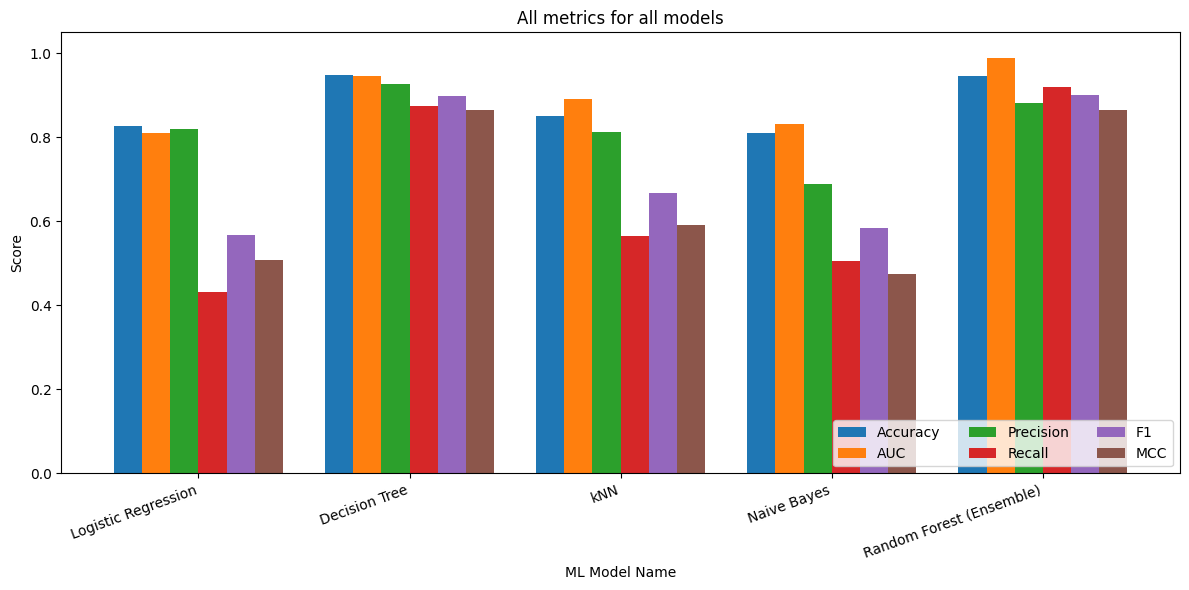

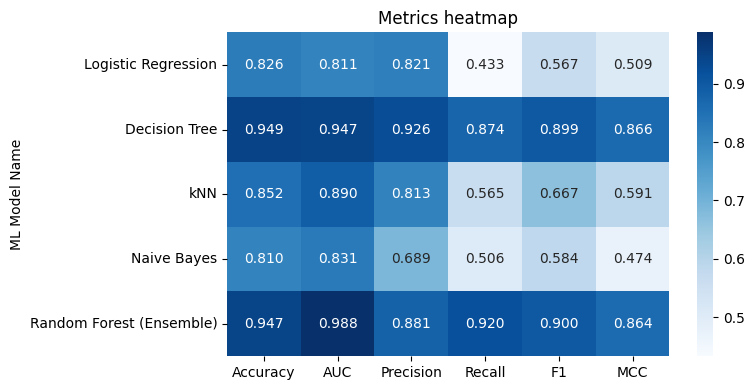

In [55]:
ax = results.plot(kind="bar", figsize=(12, 6), width=0.8)
ax.set_title("All metrics for all models")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right", ncol=3)
plt.tight_layout()
plt.savefig("metrics_comparison.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 4))
sns.heatmap(results, annot=True, fmt=".3f", cmap="Blues")
plt.title("Metrics heatmap")
plt.tight_layout()
plt.savefig("metrics_heatmap.png", dpi=150)
plt.show()

### 13. Confusion matrices

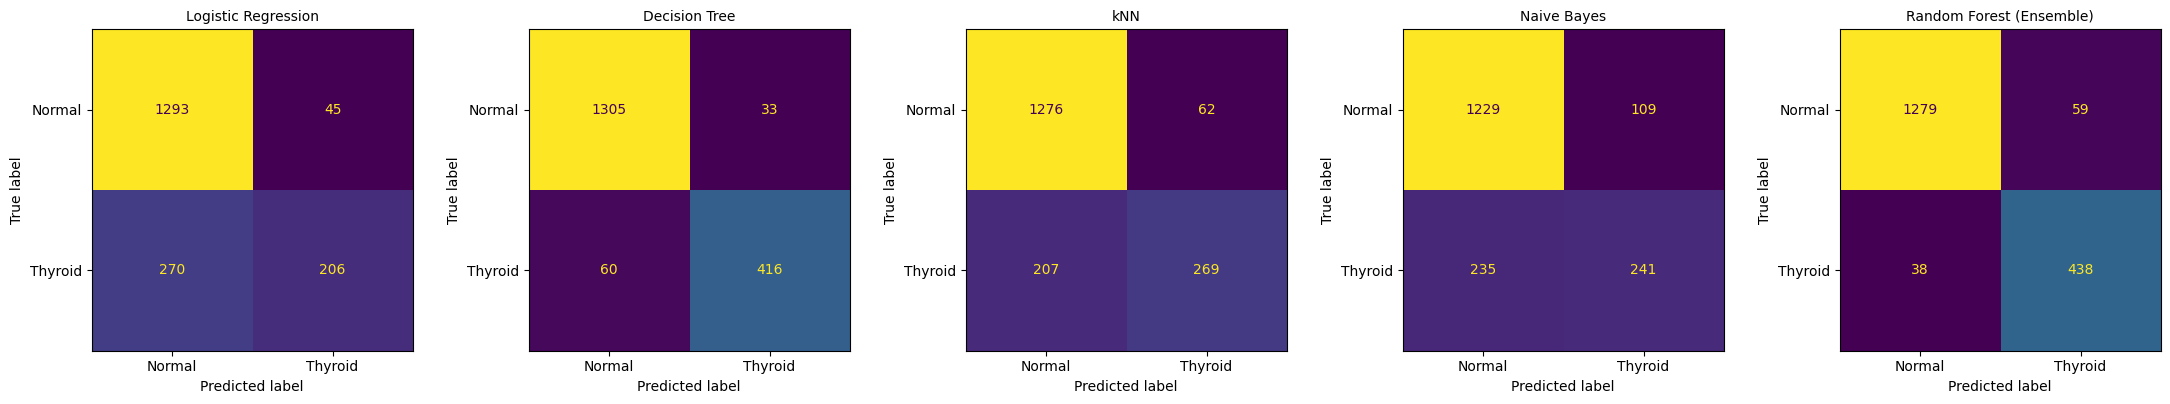

In [56]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Normal", "Thyroid"]).plot(ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

In [57]:
cm_rows = []
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    cm_rows.append({"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
cm_df = pd.DataFrame(cm_rows).set_index("Model")
print(cm_df)
print()
for name, r in cm_df.iterrows():
    sick = r["TP"] + r["FN"]
    print(f"{name}: missed {r['FN']} of {sick} thyroid patients ({r['FN']/sick*100:.1f}%), {r['FP']} false alarms")

                            TN   FP   FN   TP
Model                                        
Logistic Regression       1293   45  270  206
Decision Tree             1305   33   60  416
kNN                       1276   62  207  269
Naive Bayes               1229  109  235  241
Random Forest (Ensemble)  1279   59   38  438

Logistic Regression: missed 270 of 476 thyroid patients (56.7%), 45 false alarms
Decision Tree: missed 60 of 476 thyroid patients (12.6%), 33 false alarms
kNN: missed 207 of 476 thyroid patients (43.5%), 62 false alarms
Naive Bayes: missed 235 of 476 thyroid patients (49.4%), 109 false alarms
Random Forest (Ensemble): missed 38 of 476 thyroid patients (8.0%), 59 false alarms


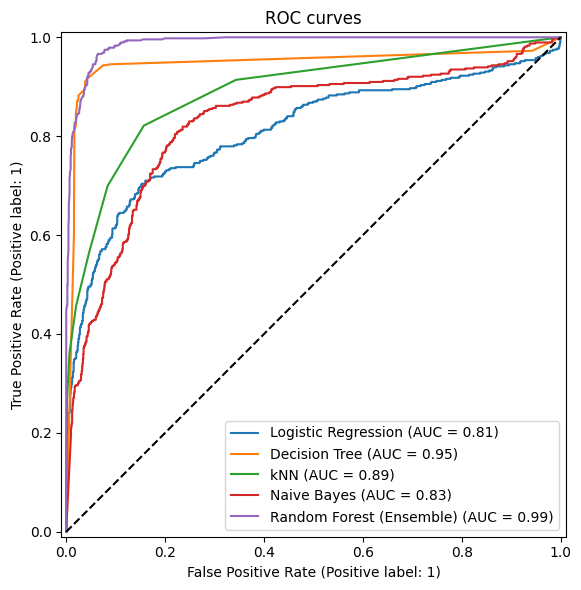

In [58]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))
for name, pipe in trained.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", label="random guess")
ax.set_title("ROC curves")
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()

### 14. Save the models

In [59]:
os.makedirs("model", exist_ok=True)
for name, pipe in trained.items():
    file_name = name.split(" (")[0].lower().replace(" ", "_")
    joblib.dump(pipe, f"model/{file_name}.joblib")
print(os.listdir("model"))

['random_forest.joblib', 'decision_tree.joblib', 'logistic_regression.joblib', 'knn.joblib', 'naive_bayes.joblib']


In [60]:
print("=" * 60)
print("DATASET FACTS")
print("=" * 60)
print(f"Raw size: {raw.shape[0]} rows x {raw.shape[1]} columns")
print(f"Impossible ages fixed: {n_bad_age} | Duplicates removed: {n_dup}")
print(f"Rows used: {len(df)} | Features used: {X.shape[1]}")
print(f"Feature types: {len(num_cols)} numeric, {len(cat_cols)} categorical, {len(flag_cols)} yes/no flags")
print(f"Class counts after cleaning: Normal={after[0]}, Thyroid={after[1]} "
      f"({after[1] / len(df) * 100:.2f}% thyroid)")
print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)}")
print("Missing values before cleaning:",
      ", ".join(f"{c} {r['percent']}%" for c, r in missing.iterrows()))

print()
print("=" * 60)
print("BEST AND WORST MODEL PER METRIC")
print("=" * 60)
for metric in results.columns:
    print(f"{metric:10s} best: {results[metric].idxmax()} ({results[metric].max():.4f}) | "
          f"worst: {results[metric].idxmin()} ({results[metric].min():.4f})")

rank = results.rank(ascending=False).mean(axis=1).sort_values()
print("\nAverage rank over the 6 metrics (1 = best):")
print(rank.round(2).to_string())
top = rank[rank == rank.min()].index.tolist()
print("\nBest average rank:", " & ".join(top))
print("Best MCC:", results["MCC"].idxmax(), "| Best recall:", results["Recall"].idxmax())

DATASET FACTS
Raw size: 9172 rows x 31 columns
Impossible ages fixed: 4 | Duplicates removed: 102
Rows used: 9070 | Features used: 27
Feature types: 6 numeric, 2 categorical, 19 yes/no flags
Class counts after cleaning: Normal=6690, Thyroid=2380 (26.24% thyroid)
Train rows: 7256 | Test rows: 1814
Missing values before cleaning: sex 3.35%, TSH 9.18%, T3 28.39%, TT4 4.82%, T4U 8.82%, FTI 8.74%, TBG 96.19%

BEST AND WORST MODEL PER METRIC
Accuracy   best: Decision Tree (0.9487) | worst: Naive Bayes (0.8104)
AUC        best: Random Forest (Ensemble) (0.9883) | worst: Logistic Regression (0.8109)
Precision  best: Decision Tree (0.9265) | worst: Naive Bayes (0.6886)
Recall     best: Random Forest (Ensemble) (0.9202) | worst: Logistic Regression (0.4328)
F1         best: Random Forest (Ensemble) (0.9003) | worst: Logistic Regression (0.5667)
MCC        best: Decision Tree (0.8658) | worst: Naive Bayes (0.4736)

Average rank over the 6 metrics (1 = best):
ML Model Name
Decision Tree           